<center><h1> Full RC Time Series Diffusion Models <h1><center>

# Table of Contents
1. [Intro](#Introduction)
2. [Data](#Data)
3. [Model Specifications](#Model-Specifications)
4. [Training](#Training)
5. [Testing](#Testing)

# Introduction

In [92]:
from google.colab import drive
drive.mount('/content/drive')

%cd "/content/drive/MyDrive/RC-Diffusion Project/RC-Diffusion-Models-for-Time-Series-Generation"
# !pip install -q lightning torchmetrics formulaic interface_meta statsmodels
# !pip install -q -e . --no-deps

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/RC-Diffusion Project/RC-Diffusion-Models-for-Time-Series-Generation


In [70]:
import torch 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
from pathlib import Path
from tqdm import tqdm 
import os

In [71]:
# ---- EDIT THESE ----
DEVICE_NAME = "cpu"  
GPU_ID = 0   # (0 or 1)
N_THREADS = 4 
# --------------------

# Make CUDA's numbering match nvidia-smi (default ordering can differ)
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU_ID) if DEVICE_NAME == "cuda" else ""
os.environ["OMP_NUM_THREADS"] = str(N_THREADS)
os.environ["MKL_NUM_THREADS"] = str(N_THREADS)

torch.set_num_threads(N_THREADS)

if DEVICE_NAME == "cuda":
    assert torch.cuda.is_available(), "CUDA requested but not available"
    device = torch.device("cuda:0")   # see note below
    free, total = torch.cuda.mem_get_info()
    print(f"Using {torch.cuda.get_device_name(0)} (physical GPU {GPU_ID}); "
          f"free {free/1e9:.1f} / {total/1e9:.1f} GB")
else:
    device = torch.device("cpu")
    print("Using CPU")

Using CPU


# Data

In [72]:
RV_PATH = 'data/SP500_RV_5min.xlsx'
PATH_RUNS = Path('runs')


STANDARDIZE = False 
LOG = True
N_TRAIN = 2000

In [73]:
raw = pd.read_excel(RV_PATH)
raw['Date'] = pd.to_datetime(raw['Date'], format='%Y%m%d')
dates = raw['Date'].to_numpy()
rv = raw['RV']
rv = torch.tensor(raw['RV'].to_numpy(), dtype=torch.float32).reshape(-1, 1)

rv_train = rv[:N_TRAIN]
rv_test = rv[N_TRAIN:]
dates_train = dates[:N_TRAIN]
dates_test = dates[N_TRAIN:]

def print_stats(x : torch.Tensor, txt : str): 
    print("****")
    print(txt)
    print('Mean :', x.mean(dim = 0).item())
    print('Standard Deviation :', x.std(dim = 0).item())
    print('Skweness :',((x - x.mean(dim = 0)) / (x.std(dim = 0) + 1e-8)**3).mean(dim = 0))
    print("****")

print_stats(rv_train, 'Stats for simple RV train set')
print_stats(rv_test, 'Stats for simple RV test set')

if LOG:
    rv_train = torch.log(rv_train)
    rv_test = torch.log(rv_test)
    PATH_RUNS = PATH_RUNS / 'rv_log'
    print_stats(rv_train, 'Stats after log transform for train set')
    print_stats(rv_test, 'Stats after log transform for test set')
else: 
    PATH_RUNS = PATH_RUNS / 'rv'

if STANDARDIZE:
    mu, std = rv_train.mean(dim = 0), rv_train.std(dim = 0)
    rv_train = (rv_train - mu)/std
    rv_test = (rv_test - mu)/std
    PATH_RUNS = PATH_RUNS / 'std'
    print_stats(rv_train, 'Stats after standardization for train set')
    print_stats(rv_test, 'Stats after standardization for test set')

if not PATH_RUNS.exists(): 
    raise ValueError('The directory to save the runs does not exists')
else: 
    print('Runs will be saved under: ', PATH_RUNS)

****
Stats for simple RV train set
Mean : 1.1942918300628662
Standard Deviation : 1.5430175065994263
Skweness : tensor([1.8001e-08])
****
****
Stats for simple RV test set
Mean : 1.1570228338241577
Standard Deviation : 2.864265203475952
Skweness : tensor([4.7490e-09])
****
****
Stats after log transform for train set
Mean : -0.18863756954669952
Standard Deviation : 0.8047213554382324
Skweness : tensor([3.7909e-08])
****
****
Stats after log transform for test set
Mean : -0.6357990503311157
Standard Deviation : 1.068070411682129
Skweness : tensor([1.5925e-08])
****
Runs will be saved under:  runs/rv_log


# Model Specifications

In [74]:
from rcdiff.diff import DDPM, BaseScheduler

K = 100
SEED = 12345

scheduler = BaseScheduler(K = K)
ddpm = DDPM(scheduler=scheduler, seed = SEED)

In [75]:
from rcdiff import ESN 
from rcdiff import RandomWeight, ParametersESN

R = 25 
T, N = rv.shape

A = RandomWeight(dist="normal", sparsity=0, norm_type="spectral_radius")
C = RandomWeight(dist="uniform", sparsity=0, norm_type="l2")
zeta = RandomWeight(dist="uniform", sparsity=0, norm_type="euclidean")

esnParams = ParametersESN(A_RW = A, 
                 C_RW = C,
                 zeta_RW = zeta,
                 leak_rate = 0.3, 
                 rho = 0.9, 
                 gamma = 0.35,
                 omega = 0) 

esn = ESN(in_dim = N, 
          reservoir_size= R, 
          params=esnParams
          )

In [68]:
from rcdiff import RWDenoisingNetwork, ParametersRWDN

H = 50

A_k = RandomWeight("uniform", sparsity=0, norm_type="l2")
b_k = RandomWeight("uniform", sparsity=0, norm_type="euclidean")

rwdnParams = ParametersRWDN(A_k = A_k,
               b_k = b_k,
               gamma = 0.7, 
               omega = 0.4)

rwdn = RWDenoisingNetwork(in_dim = N, 
                          hidden_size = H, 
                          reservoir_size = R,
                          params = rwdnParams, 
                          K = K)

In [76]:
from rcdiff.models.config import TrainConfig

train_spec = TrainConfig(t0 = 100,
                        seed = SEED,
                        device = "cpu")  

In [77]:
from rcdiff import RCDiff 

rcdiffusion = RCDiff(diff = ddpm, esn = esn, denoiser = rwdn, spec = train_spec)

# Training

In [78]:
df_loss, time = rcdiffusion.fit(x = rv_train, c = None)

100


100%|██████████| 100/100 [00:00<00:00, 116.43it/s]


Training complete Time: 0.86s
100


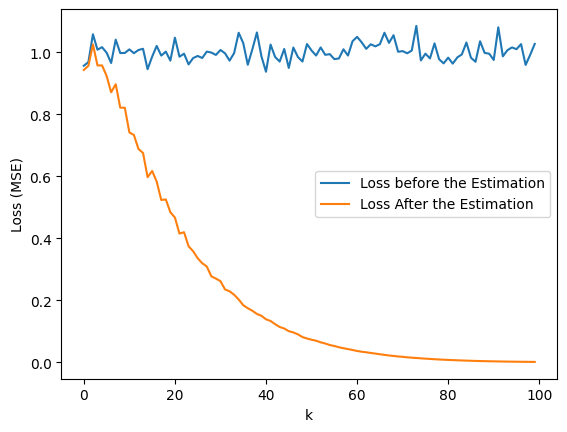

In [79]:
plt.plot(df_loss['k'], df_loss['LossBefore'], label = 'Loss before the Estimation')
plt.plot(df_loss['k'], df_loss['LossAfter'], label = 'Loss After the Estimation')
plt.ylabel('Loss (MSE)')
plt.xlabel('k')
plt.legend()
plt.show()

# Testing

A one step ahead can be performed by: 

In [80]:
x_hat, full_reverse = rcdiffusion.conditional_distribution(x = rv_train, c = None, n_samples=100)
print('Actual obs', round(rv_test[0].item(),2))
print('Predicted obs', round(x_hat[0].mean().item(), 2))

Actual obs -0.4
Predicted obs -1.09


In [81]:
forecast = rcdiffusion.one_step_ahead_forecast(x_train = rv_train, x_test = rv_test)

100%|██████████| 2096/2096 [01:42<00:00, 20.43it/s]


In [ ]:
F_m = forecast.squeeze(2).mean(dim = 1)

if LOG:
    F = torch.exp(F_m)
    test = torch.exp(rv_test)
else: 
    F = F_m.clone()
    test = rv_test.clone()

def qlike(actual, pred):
    r = actual/pred # when pred --> large this goes to zero so
    return torch.mean(r - (torch.log(actual) - torch.log(pred))-1) # NOTE: change this one

def mse(actual, pred):
    return torch.mean((actual-pred)**2)

def mae(actual, pred):
    return torch.mean(torch.abs(actual-pred))


mse_test = mse(test.squeeze(1), F)
mae_test = mae(test.squeeze(1), F)
qlike_test = qlike(test.squeeze(1), F)

print('MSE of the test:', mse_test)
print('MAE of the test:', mae_test)
print('QLIKE of the test:', qlike_test)

MSE of the test: tensor(3.9339)
MAE of the test: tensor(0.4826)
QLIKE of the test: tensor(0.1518)


In [89]:
print('Predicted out of sample mean:', F.mean(dim = 0))
print('Predicted out of sample mean:', test.flatten().mean())
print('Predicted out of sample mean:', F.std(dim = 0))
print('Predicted out of sample mean:', test.flatten().std())

Predicted out of sample mean: tensor(0.9224)
Predicted out of sample mean: tensor(1.1570)
Predicted out of sample mean: tensor(1.5604)
Predicted out of sample mean: tensor(2.8643)


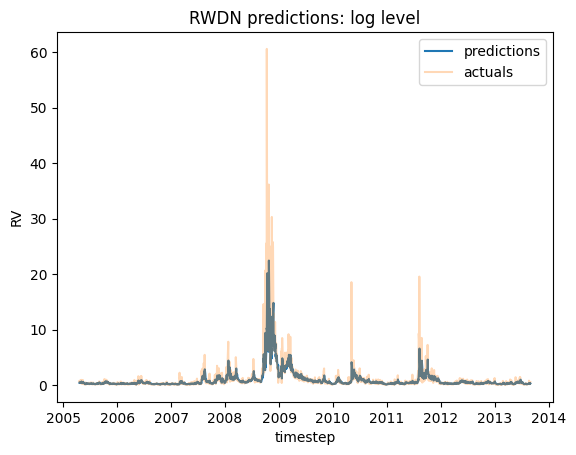

In [83]:
predictions_df = pd.DataFrame({'predictions' : F.detach().numpy().flatten(), 
                               'true' : test.detach().numpy().flatten()}, 
                            index = dates_test
                            )

plt.title('RWDN predictions: log level' if LOG else 'RWDN predictions: level')
plt.plot(predictions_df.index, predictions_df['predictions'], label = 'predictions')
plt.plot(predictions_df.index, predictions_df['true'], label = 'actuals', alpha = 0.3)
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.show()

In [101]:
import pandas as pd

pd.read_csv('runs/forced/results.csv', index_col = 0)

,test_0,test_1,test_2,test_3
K,100.000000,100.000000,100.000000,100.000000
R,25.000000,25.000000,25.000000,25.000000
rho,0.900000,0.900000,0.900000,0.900000
leak_rate,0.300000,0.300000,0.300000,0.300000
gamma,0.200000,0.250000,0.300000,0.350000
qlike_test,0.146536,0.147141,0.155347,0.145864
mse_test,3.574331,3.599566,4.075506,3.515114
mae_test,0.478982,0.478383,0.491879,0.474620


In [98]:
import pandas as pd
pred = pd.read_csv('runs/predictions_paper_jordi_mika.csv', index_col = 0)

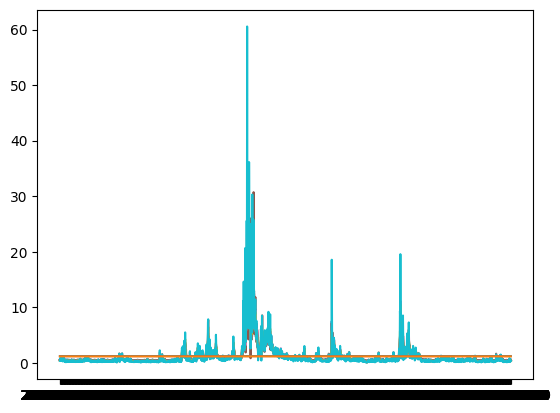

In [ ]:
import matplotlib.pyplot as plt 

fig, ax = plt.subplots(1,len(pred.columns))
for col in pred.columns: 

    ax[i].plot(pred.index, pred[col])
    plt.show
